# RT-DETR

Para el environments usar el fichero requirements.txt de https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch. No requiere de ninguna librería propia.

In [ ]:
import os, sys, subprocess, urllib.request
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in mscoco_label2category.items()}  # 0..79
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [2]:
from load_rtdetr import load_rtdetr
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

@torch.no_grad()
def detect(bgr, conf=0.6):
    
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    return boxes[keep], scores[keep], labels[keep]

Cargando RT-DETR familia 'v2', tamaño 'l' en cpu
Load PResNet50 state_dict


(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

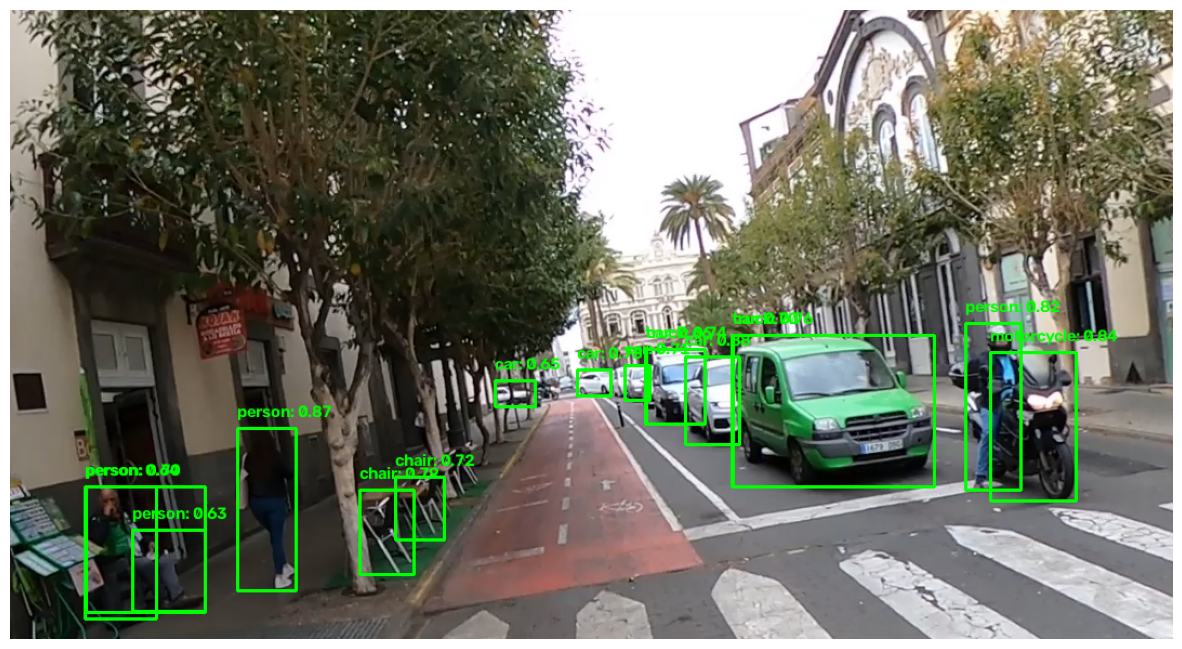

In [ ]:
# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'
image = cv2.imread(path_test)
boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')



In [4]:
# Ejemplo de uso parecido al de YOLO. Detectar entrada desde la webcam.
vid = cv2.VideoCapture(0)

while True:
    ret, img = vid.read()

    if ret:
        boxes, scores, labels = detect(img, conf=0.4)
        for (x1, y1, x2, y2), score, cls in zip(boxes, scores, labels):
            color = tuple(int(c) for c in np.random.RandomState(int(cls)).randint(50, 255, 3))  # BGR
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), color, 3)
            cv2.putText(img, f"{CLASS_NAMES[int(cls)]} {score:.2f}", (int(x1), max(int(y1) - 8, 20)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

        cv2.imshow("Vid", img)

    # Detenemos pulsando ESC
    if cv2.waitKey(1) == 27: break

vid.release()
cv2.destroyAllWindows()

# Tarea 1: Detección de coches, personas, matrículas.

In [8]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [6]:
import cv2, os
import pandas as pd
from ultralytics import YOLO
from collections import defaultdict

# CONFIGURACION
VIDEO = "C0142.MP4"
MODEL = "yolo11s.pt"
PLATE_MODEL = "best.pt"
OUTPUT = "video_procesado.mp4"
CSV = "detecciones.csv"

CONF = 0.35
PLATE_CONF = 0.25
IMGSZ = 960

CLASSES = [0, 2, 3, 5, 7]
NAMES = {0: "persona", 2: "coche", 3: "moto", 5: "autobus", 7: "camion"}
VEHICLES = [2, 3, 5, 7]

BOX_THICKNESS = 1
FONT_SCALE = 0.35
FONT_THICKNESS = 1

# CARGAR MODELOS
print("Cargando modelos...")
model = YOLO(MODEL)
plate_model = YOLO(PLATE_MODEL) if os.path.exists(PLATE_MODEL) else None

# ABRIR VIDEO
cap = cv2.VideoCapture(VIDEO)
if not cap.isOpened(): raise Exception("No se pudo abrir el video.")

fps = cap.get(cv2.CAP_PROP_FPS) or 25
width, height = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

out = cv2.VideoWriter(OUTPUT, cv2.VideoWriter_fourcc(*"mp4v"), fps, (width, height))
if not out.isOpened(): raise Exception("No se pudo crear el video.")

# VARIABLES
data = []
counts = defaultdict(set)
frame_number = 0

# PROCESAMIENTO
while True:
    ret, frame = cap.read()
    if not ret: break

    frame_number += 1
    print(f"Procesando {frame_number}/{total}", end="\r")

    result = model.track(frame, persist=True, tracker="bytetrack.yaml", classes=CLASSES, conf=CONF, imgsz=IMGSZ, verbose=False)[0]
    annotated = frame.copy()

    if result.boxes is not None:
        for box in result.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0].cpu().numpy())
            confidence, cls = float(box.conf[0]), int(box.cls[0])
            name = NAMES[cls]
            track_id = int(box.id[0]) if box.id is not None else -1

            if track_id != -1: counts[name].add(track_id)

            cv2.rectangle(annotated, (x1, y1), (x2, y2), (0, 255, 0), BOX_THICKNESS)
            cv2.putText(annotated, f"{name} {track_id} {confidence:.2f}", (x1, max(y1 - 4, 12)), cv2.FONT_HERSHEY_SIMPLEX, FONT_SCALE, (0, 255, 0), FONT_THICKNESS)

            plate_confidence = 0
            mx1 = my1 = mx2 = my2 = None

            if plate_model is not None and cls in VEHICLES:
                crop = frame[max(0, y1):min(height, y2), max(0, x1):min(width, x2)]

                if crop.size > 0:
                    plates = plate_model.predict(crop, conf=PLATE_CONF, imgsz=640, verbose=False)[0]

                    if plates.boxes is not None and len(plates.boxes):
                        best = max(plates.boxes, key=lambda b: float(b.conf[0]))
                        px1, py1, px2, py2 = map(int, best.xyxy[0].cpu().numpy())
                        mx1, my1, mx2, my2 = x1 + px1, y1 + py1, x1 + px2, y1 + py2
                        plate_confidence = float(best.conf[0])

                        cv2.rectangle(annotated, (mx1, my1), (mx2, my2), (255, 0, 0), 1)
                        cv2.putText(annotated, "PLACA", (mx1, max(my1 - 3, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.3, (255, 0, 0), 1)

            data.append({"fotograma": frame_number, "tipo_objeto": name, "confianza": confidence, "identificador_tracking": track_id, "x1": x1, "y1": y1, "x2": x2, "y2": y2, "confianza_matricula": plate_confidence, "mx1": mx1, "my1": my1, "mx2": mx2, "my2": my2})

    y = 20
    for name, ids in counts.items():
        cv2.putText(annotated, f"{name}: {len(ids)}", (10, y), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 255, 255), 1)
        y += 18

    out.write(annotated)

# FINALIZAR
cap.release()
out.release()
cv2.destroyAllWindows()

# EXPORTAR CSV
df = pd.DataFrame(data)
df.to_csv(CSV, index=False, encoding="utf-8-sig")

# RESULTADOS
print("\n\nPROCESAMIENTO FINALIZADO")
for name, ids in counts.items(): print(f"{name}: {len(ids)}")
print(f"\nTotal de detecciones: {len(df)}")
print(f"Video: {OUTPUT}")
print(f"CSV: {CSV}")

Cargando modelos...
Procesando 2832/2832

PROCESAMIENTO FINALIZADO
autobus: 9
coche: 273
persona: 91
camion: 37
moto: 5

Total de detecciones: 29335
Video: video_procesado.mp4
CSV: detecciones.csv
